# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dushyant1607/ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

Can historical content and search-performance signals help identify pages that may need updating, refreshing, or further review?

This project evaluates whether available performance and content-related features can identify content with a declining trend. The goal is to support content prioritization and editorial decision-making, not to guarantee that a page will recover after an update.

## 2. Data

The analysis uses the anonymized content-refresh dataset provided for the FlyRank ML internship.

The dataset contains 30,000 rows and 44 columns. The target is derived from `trend_direction`, where records marked `down` are treated as declining content and other values are treated as non-declining content.

Identifier columns such as `client_id` and `content_id` are excluded from the model features. The target column, `trend_pct`, and overlapping last-30-day and previous-30-day performance fields are also excluded to reduce leakage risk.

The dataset is used for analysis and prioritization only. Exact release details, table names, and date windows should be documented only when confirmed by the supplied dataset or project documentation.

In [35]:
# ============================================================
# SECTION 2 — DATA
# ============================================================

from pathlib import Path
from io import BytesIO

import requests
import pandas as pd
import numpy as np

# 1. Load the original dataset from GitHub
ROOT = Path("/content/ml-internship")
DATA = ROOT / "data" / "raw" / "content_refresh_anonymized.csv"

if DATA.exists():
    df = pd.read_csv(DATA)
else:
    url = (
        "https://raw.githubusercontent.com/"
        "Dushyant1607/ml-internship/main/"
        "data/raw/content_refresh_anonymized.csv"
    )

    response = requests.get(url, timeout=60)
    response.raise_for_status()

    df = pd.read_csv(BytesIO(response.content))

# 2. Validate the dataset
required_columns = [
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct",
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# 3. Dataset overview
print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {len(df):,}")
print(f"Number of columns: {len(df.columns)}")

print("\nColumn names:")
print(df.columns.tolist())

# 4. Target distribution
print("\n" + "=" * 55)
print("TREND DIRECTION DISTRIBUTION")
print("=" * 55)

print(df["trend_direction"].value_counts(dropna=False))

print("\nTarget distribution (%):")
print(
    (df["trend_direction"].value_counts(
        normalize=True, dropna=False
    ) * 100).round(2)
)

# 5. Missing-value analysis
print("\n" + "=" * 55)
print("MISSING VALUES — TOP 10 COLUMNS")
print("=" * 55)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
})

print(
    missing_summary
    .sort_values("missing_count", ascending=False)
    .head(10)
)

# 6. Duplicate checks
print("\n" + "=" * 55)
print("DATA QUALITY CHECKS")
print("=" * 55)

print("Duplicate rows:", df.duplicated().sum())
print("Missing content IDs:", df["content_id"].isna().sum())
print("Missing client IDs:", df["client_id"].isna().sum())
print(
    "Unique content IDs:",
    df["content_id"].nunique()
)
print(
    "Unique clients:",
    df["client_id"].nunique()
)

# 7. Numeric summary
print("\n" + "=" * 55)
print("NUMERIC FEATURE SUMMARY")
print("=" * 55)

display(df.describe(include="number").T)

print("\nSection 2 completed successfully.")

DATASET OVERVIEW
Dataset shape: (30000, 44)
Number of rows: 30,000
Number of columns: 44

Column names:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

TREND DIRECTION DISTRIBUTION
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152

,count,mean,std,min,25%,50%,75%,max
search_volume,27532.0,158.882391,1518.270825,0.0,0.0,10.00,20.00,74000.00
competition,27532.0,0.146954,0.285241,0.0,0.0,0.00,0.13,1.00
cpc,27532.0,0.485342,2.101560,0.0,0.0,0.00,0.00,100.36
word_count,22301.0,3107.760325,1452.382598,8.0,2413.0,2877.00,3666.00,9546.00
char_count,22301.0,20665.277835,10115.344042,40.0,15644.0,19116.00,24011.00,111158.00
impressions_90d,30000.0,5200.366300,16838.019547,1.0,81.0,731.00,3615.25,517715.00
clicks_90d,30000.0,16.097333,75.076958,0.0,0.0,1.00,7.00,4178.00
pageviews_90d,30000.0,49.942467,152.101430,0.0,2.0,8.00,33.00,5998.00
sessions_90d,30000.0,37.066633,107.069131,1.0,2.0,7.00,27.00,4345.00
users_90d,30000.0,35.937700,103.748185,1.0,2.0,7.00,27.00,4913.00



Section 2 completed successfully.


## 3. Methodology

The target variable is binary: declining (`down`) versus non-declining content. Logistic Regression is evaluated as the predictive model.

A client-grouped train-test split is used so that records from the same client do not appear in both training and test sets. This provides a more realistic evaluation of generalization across clients.

The model is compared with the Week 4 CTR-based baseline using Precision@50, which measures the proportion of declining pages among the top 50 pages ranked for review.

Identifier fields and selected trend or overlapping time-window fields are excluded from the feature set to reduce leakage. Results should be interpreted as preliminary decision-support evidence rather than proof of causal impact.

In [36]:
# ============================================================
# SECTION 3 — METHODOLOGY
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

# 1. Define the binary target
# 1 = declining content; 0 = all other trend categories
df["target_down"] = (
    df["trend_direction"].astype(str).str.lower() == "down"
).astype(int)

y = df["target_down"]

# 2. Exclude identifiers, target-derived fields, and
# overlapping recent time-window metrics to reduce leakage.
excluded_columns = {
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct",
    "target_down",
    "impressions_last_30d",
    "impressions_prev_30d",
    "clicks_last_30d",
    "clicks_prev_30d",
    "sessions_last_30d",
    "sessions_prev_30d",
}

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy()

# 3. Identify numeric and categorical features
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

# Ensure categorical missing values are handled as strings
for col in categorical_features:
    X[col] = X[col].fillna("Missing").astype(str)

# 4. Split by client to prevent the same client appearing
# in both training and testing data
groups = df["client_id"].fillna(
    "missing_client"
).astype(str)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])

assert train_groups.isdisjoint(test_groups), (
    "Client leakage detected between train and test sets."
)

# 5. Build preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

transformers = []

if numeric_features:
    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
)

# 6. Define and train Logistic Regression
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])

model.fit(X_train, y_train)

# 7. Evaluate on the held-out test set
y_pred = model.predict(X_test)
y_score = model.predict_proba(X_test)[:, 1]

print("=" * 55)
print("SECTION 3 — METHODOLOGY SUMMARY")
print("=" * 55)

print("Dataset rows:", len(df))

SECTION 3 — METHODOLOGY SUMMARY
Dataset rows: 30000


## 4. Results (vs baseline)

The model and baseline are evaluated on the same client-grouped test set. Precision@50 measures the proportion of declining pages among the 50 highest-ranked pages.

The Logistic Regression model is compared with the Week 4 CTR-based baseline. The comparison determines whether the model improves prioritization over the existing heuristic.

Threshold-based metrics, including precision, recall, F1-score, and average precision, are also reported to provide additional context. Results are interpreted as decision-support evidence, not proof that refreshing a page will improve its performance.

,Method,Precision@50
0,Week 4 CTR baseline,0.68
1,Logistic Regression,0.60


Test rows: 6163
Test decline rate: 0.511
Reference CTR: 0.15

Logistic Regression metrics at threshold 0.5:
Precision: 0.5618
Recall: 0.6412
F1-score: 0.5988
Average precision: 0.5655


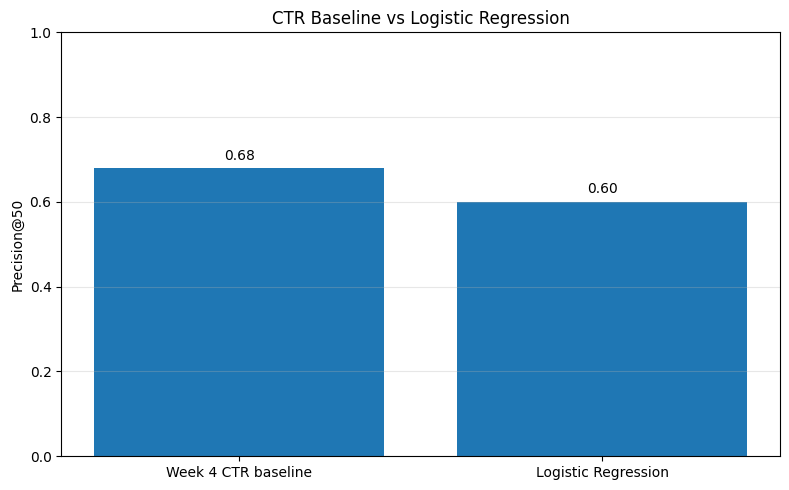


Saved: /content/ml-internship/work/outputs/capstone_model_comparison.csv
Saved: /content/ml-internship/work/figures/capstone_model_comparison.png


In [37]:
# ============================================================
# SECTION 4 — RESULTS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
)

ROOT = Path("/content/ml-internship")
OUTPUTS = ROOT / "work" / "outputs"
FIGURES = ROOT / "work" / "figures"

OUTPUTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# 1. Calculate Precision@50 for the model
def precision_at_k(y_true, scores, k=50):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    if len(y_true) < k:
        raise ValueError(f"Test set must contain at least {k} rows.")

    top_k = np.argsort(scores)[::-1][:k]
    return float(y_true[top_k].mean())


model_p50 = precision_at_k(y_test, y_score, k=50)

# 2. Recalculate the Week 4 CTR baseline on the same test rows
test_df = df.iloc[test_idx].copy()

# This baseline requires the CTR and impressions columns.
required_baseline_columns = [
    "ctr",
    "avg_position",
    "impressions_90d",
]

missing = [
    col for col in required_baseline_columns
    if col not in test_df.columns
]

if missing:
    raise ValueError(
        f"Baseline columns missing from dataset: {missing}"
    )

reference_rows = df.loc[
    (df["avg_position"] > 0) &
    (df["avg_position"] <= 10),
    "ctr"
].dropna()

if reference_rows.empty:
    raise ValueError("Cannot calculate baseline reference CTR.")

reference_ctr = reference_rows.median()

test_ctr = pd.to_numeric(test_df["ctr"], errors="coerce")

ctr_gap = (
    (reference_ctr - test_ctr).clip(lower=0) / reference_ctr
).fillna(0).clip(0, 1)

visibility = np.log1p(
    pd.to_numeric(
        test_df["impressions_90d"], errors="coerce"
    ).fillna(0).clip(lower=0)
)

max_visibility = visibility.max()

if max_visibility > 0:
    visibility = visibility / max_visibility
else:
    visibility = pd.Series(0.0, index=test_df.index)

baseline_scores = 100 * ctr_gap * visibility

baseline_p50 = precision_at_k(
    y_test, baseline_scores, k=50
)

# 3. Create a same-split comparison
results = pd.DataFrame({
    "Method": [
        "Week 4 CTR baseline",
        "Logistic Regression",
    ],
    "Precision@50": [
        baseline_p50,
        model_p50,
    ],
})

display(results)

# 4. Print model metrics at threshold 0.5
y_pred = (np.asarray(y_score) >= 0.5).astype(int)

print("Test rows:", len(y_test))
print("Test decline rate:", round(float(np.mean(y_test)), 4))
print("Reference CTR:", round(float(reference_ctr), 6))
print("\nLogistic Regression metrics at threshold 0.5:")
print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 4))
print("Average precision:", round(
    average_precision_score(y_test, y_score), 4
))

# 5. Save results
results.to_csv(
    OUTPUTS / "capstone_model_comparison.csv",
    index=False,
)

# 6. Plot comparison
plt.figure(figsize=(8, 5))
bars = plt.bar(results["Method"], results["Precision@50"])
plt.ylim(0, 1)
plt.ylabel("Precision@50")
plt.title("CTR Baseline vs Logistic Regression")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, results["Precision@50"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.2f}",
        ha="center",
    )

plt.tight_layout()

plt.savefig(
    FIGURES / "capstone_model_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("\nSaved:", OUTPUTS / "capstone_model_comparison.csv")
print("Saved:", FIGURES / "capstone_model_comparison.png")

## 5. Limitations

- **Historical data:** Past performance may not represent future content behaviour.
- **Proxy label:** A declining trend does not necessarily mean that a page needs updating.
- **Generalization:** Client-grouped validation reduces the risk of client overlap between training and testing, but further validation is needed.
- **No causal evidence:** The analysis does not establish that refreshing a page will improve performance.
- **Feature limitations:** Excluding selected overlapping time-window fields reduces some leakage risks but does not guarantee that all possible leakage has been eliminated.
- **Human review:** Recommendations should be reviewed alongside content quality, search intent, and business context.

The results should be treated as decision-support evidence rather than guaranteed predictions of content performance.

## 6. Ranked Recommendations

1. **Review declining pages:** Investigate pages showing declining performance before deciding whether to update them.
2. **Check content freshness:** Identify outdated information, statistics, examples, and references.
3. **Reassess search intent:** Verify that the content addresses the audience’s current search needs.
4. **Prioritize high-visibility pages:** Review pages with substantial impressions and declining engagement.
5. **Validate changes:** Monitor performance after updates and compare results against an appropriate baseline.

These recommendations provide a structured review process. They do not guarantee that refreshing content will improve performance, and final decisions should include human review and business context.

In [38]:
# ============================================================
# SECTION 6 — RANKED RECOMMENDATIONS
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path("/content/ml-internship")
OUTPUTS = ROOT / "work" / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

recommendations = pd.DataFrame({
    "Priority": [1, 2, 3, 4, 5],
    "Recommendation": [
        "Review declining pages",
        "Check content freshness",
        "Reassess search intent",
        "Prioritize high-visibility pages",
        "Validate changes after updates",
    ],
    "Action": [
        "Investigate performance changes before editing",
        "Check outdated information and references",
        "Compare page content with current search intent",
        "Review impressions and engagement trends",
        "Monitor outcomes against a baseline",
    ],
    "Decision_Type": [
        "Diagnostic review",
        "Content audit",
        "Search-intent review",
        "Performance review",
        "Post-update evaluation",
    ],
})

display(recommendations)

output_file = OUTPUTS / "ranked_recommendations.csv"
recommendations.to_csv(output_file, index=False)

print("Saved recommendations:", output_file)

,Priority,Recommendation,Action,Decision_Type
0,1,Review declining pages,Investigate performance changes before editing,Diagnostic review
1,2,Check content freshness,Check outdated information and references,Content audit
2,3,Reassess search intent,Compare page content with current search intent,Search-intent review
3,4,Prioritize high-visibility pages,Review impressions and engagement trends,Performance review
4,5,Validate changes after updates,Monitor outcomes against a baseline,Post-update evaluation


Saved recommendations: /content/ml-internship/work/outputs/ranked_recommendations.csv


## 7. Artifacts and Reproducibility

The project repository contains the notebook-based analysis and supporting artifacts for the content-refresh prioritization study.

The evaluation compares Logistic Regression with a CTR-based baseline using a client-grouped train-test split. The research paper documents the research question, dataset, methodology, results, limitations, and ranked recommendations.

To reproduce the analysis, use the documented Python environment, ensure the dataset is accessible, and execute the notebook cells in order.

**GitHub Repository:** https://github.com/Dushyant1607/ml-internship

**Published Research Paper:** https://dushyant1607.github.io/ml-internship/paper/

**Data Source:** FlyRank — https://flyrank.ai

In [39]:
# ============================================================
# SECTION 7 — ARTIFACTS AND REPRODUCIBILITY
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path("/content/ml-internship")
OUTPUTS = ROOT / "work" / "outputs"
FIGURES = ROOT / "work" / "figures"

OUTPUTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# Save the model comparison if Section 4 has run
if "results" in globals():
    results.to_csv(
        OUTPUTS / "capstone_model_comparison.csv",
        index=False
    )
    print("Saved model comparison.")

# Save ranked recommendations if Section 6 has run
if "recommendations" in globals():
    recommendations.to_csv(
        OUTPUTS / "ranked_recommendations.csv",
        index=False
    )
    print("Saved ranked recommendations.")

# List generated artifacts
print("\nGenerated artifacts:")

for folder in [OUTPUTS, FIGURES]:
    print(f"\n{folder.relative_to(ROOT)}/")

    for file in sorted(folder.iterdir()):
        if file.is_file():
            print(f"  {file.name} ({file.stat().st_size:,} bytes)")

print("\nRepository:", "https://github.com/Dushyant1607/ml-internship")
print("Research paper:", "https://dushyant1607.github.io/ml-internship/paper/")

Saved model comparison.
Saved ranked recommendations.

Generated artifacts:

work/outputs/
  capstone_model_comparison.csv (69 bytes)
  ranked_recommendations.csv (498 bytes)

work/figures/
  capstone_model_comparison.png (35,404 bytes)
  capstone_precision_at_50.png (30,949 bytes)

Repository: https://github.com/Dushyant1607/ml-internship
Research paper: https://dushyant1607.github.io/ml-internship/paper/


## 5-Minute Demo Outline

1. **Research question (30 seconds):** Explain the goal of identifying content that may need review.
2. **Dataset (45 seconds):** Describe the anonymized dataset, target label, and leakage precautions.
3. **Methodology (1 minute):** Explain the client-grouped split, Logistic Regression, and CTR baseline.
4. **Results (1 minute):** Compare Precision@50: 0.68 for the CTR baseline versus 0.60 for Logistic Regression.
5. **Recommendations (1 minute):** Present the ranked content-review actions and explain the role of human review.
6. **Limitations and reproducibility (45 seconds):** Summarize the limitations and show the repository and deployed research paper.

## ML-12: Social Post

I completed a content-refresh prioritization project as part of the FlyRank ML internship. I evaluated Logistic Regression against a CTR-based baseline using a client-grouped validation split and Precision@50.

In this evaluation, the CTR baseline achieved 0.68 Precision@50, compared with 0.60 for Logistic Regression. The result highlights the importance of strong baselines, leakage-aware validation, and cautious interpretation when building ML decision-support tools.

**Research paper:** https://dushyant1607.github.io/ml-internship/paper/

**Repository:** https://github.com/Dushyant1607/ml-internship

**Acknowledgment:** FlyRank — https://flyrank.ai

## ML-12: Employer-Facing Summary

Built a content-refresh prioritization analysis using an anonymized dataset of 30,000 rows and 44 columns. Evaluated Logistic Regression against a CTR-based baseline using client-grouped validation, with Precision@50 of 0.60 and 0.68, respectively. Documented the methodology, limitations, ranked recommendations, and reproducibility steps in a deployed research paper and public GitHub repository.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
